In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression




In [ ]:
df= pd.read_csv("/content/Iris.csv")
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [ ]:
df = df.drop_duplicates()
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
df = df.dropna()
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
(df.isnull().sum())

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [ ]:
df.shape

(150, 6)

In [ ]:
df = df.drop('Id',axis=1)
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
le = LabelEncoder()
df["Species"] = le.fit_transform(df["Species"])
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
df["Sepal_Area"] = df["SepalLengthCm"] * df["SepalWidthCm"]
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Sepal_Area
0,5.1,3.5,1.4,0.2,0,17.85
1,4.9,3.0,1.4,0.2,0,14.70
2,4.7,3.2,1.3,0.2,0,15.04
3,4.6,3.1,1.5,0.2,0,14.26
4,5.0,3.6,1.4,0.2,0,18.00
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,20.10
146,6.3,2.5,5.0,1.9,2,15.75
147,6.5,3.0,5.2,2.0,2,19.50
148,6.2,3.4,5.4,2.3,2,21.08


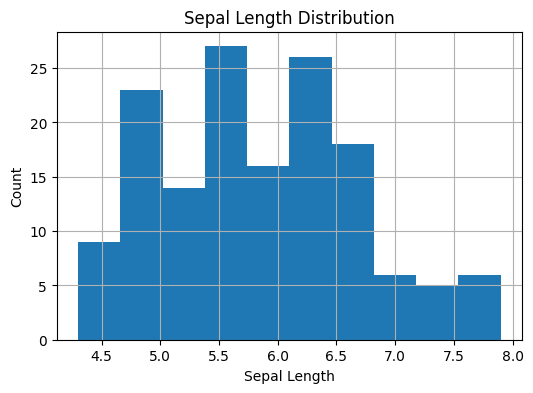

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(df["SepalLengthCm"])
plt.title("Sepal Length Distribution")
plt.xlabel("Sepal Length")
plt.ylabel("Count")
plt.grid(True)
plt.show()

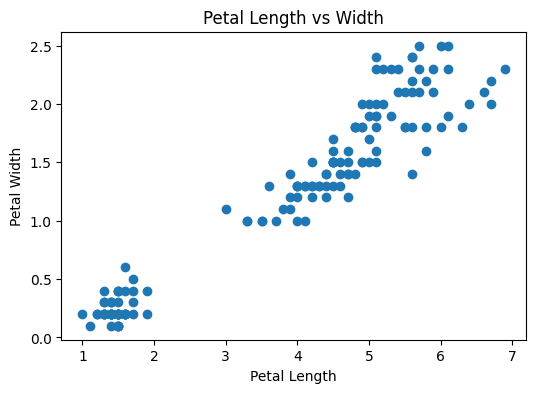

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df["PetalLengthCm"], df["PetalWidthCm"])
plt.title("Petal Length vs Width")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.show()

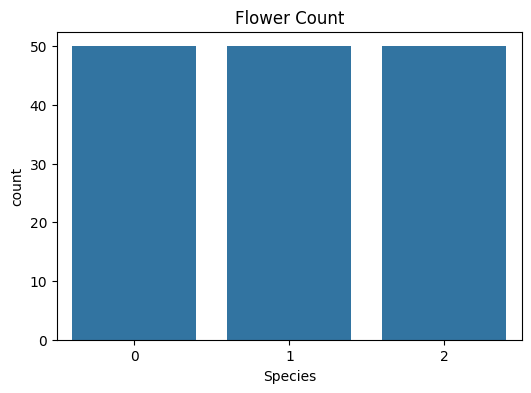

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="Species", data=df)
plt.title("Flower Count")
plt.show()

In [ ]:
X = df.drop("Species" , axis=1)
Y = df["Species"]
X_train, X_test, Y_train, Y_test = train_test_split(X,
                                                             Y,
                                                             test_size=0.2,
                                                             random_state=42)

df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Sepal_Area
0,5.1,3.5,1.4,0.2,0,17.85
1,4.9,3.0,1.4,0.2,0,14.70
2,4.7,3.2,1.3,0.2,0,15.04
3,4.6,3.1,1.5,0.2,0,14.26
4,5.0,3.6,1.4,0.2,0,18.00
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,20.10
146,6.3,2.5,5.0,1.9,2,15.75
147,6.5,3.0,5.2,2.0,2,19.50
148,6.2,3.4,5.4,2.3,2,21.08


In [ ]:
dt_model  = DecisionTreeClassifier()
dt_model.fit(X_train, Y_train)

DecisionTreeClassifier()

In [ ]:
dt_pred = dt_model.predict(X_test)
dt_pred

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0])

In [ ]:
dt_accuracy = accuracy_score(Y_test, dt_pred)
("Decision Tree Accuracy:", dt_accuracy)

('Decision Tree Accuracy:', 1.0)

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, Y_train)

KNeighborsClassifier()

In [ ]:
knn_pred = knn_model.predict(X_test)
knn_pred

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 1,
       0, 2, 2, 2, 2, 2, 0, 0])

In [ ]:
knn_accuracy = accuracy_score(Y_test, knn_pred)
print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.9666666666666667


In [ ]:
new_data = [[5.1, 3.5, 1.4, 0.2, 17.85]]
prediction = dt_model.predict(new_data)
print("Prediction Class:", prediction)

Prediction Class: [0]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [ ]:
flower_name = le.inverse_transform(prediction)
print("Prediction Flower:", flower_name)

Prediction Flower: ['Iris-setosa']


In [ ]:
if dt_accuracy > knn_accuracy:
    print("Decision Tree performed better because it achieved higher accuracy.")
else:
    print("KNN performed better because it achieved higher accuracy.")

Decision Tree performed better because it achieved higher accuracy.


In [ ]:
print("Limitations:")
print("- Small dataset")
print("- Accuracy may change with different data")
print("- Model is not 100% accurate")

Limitations:
- Small dataset
- Accuracy may change with different data
- Model is not 100% accurate
